In [2]:
import numpy as np
import re
import mmap
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import random

### Funciones preliminares

In [3]:
def log_ngram_file_to_matrix(filepath, n):
    ngram = np.zeros((26,) * n, dtype = np.uint8)

    pattern = re.compile(rb'([A-Z]{' + str(n).encode() + rb'})\s*(\d{1,3})')

    with open(filepath, 'rb') as f:
        with mmap.mmap(f.fileno(), 0, access=mmap.ACCESS_READ) as data:
            for match in pattern.finditer(data):
    
                gram = match.group(1)
                value = int(match.group(2))
    
                if value > 255:
                    raise ValueError(f"Invalid n-gram value: {value}")
    
                idx = tuple(x - ord('A') for x in gram)
    
                ngram[idx] = value

    return ngram

In [4]:
log2gram = log_ngram_file_to_matrix("2-grams_english_beijinghouse_10TB_v7.txt", 2)

In [5]:
log3gram = log_ngram_file_to_matrix("3-grams_english_beijinghouse_10TB_v7.txt", 3)

In [6]:
log6gram = log_ngram_file_to_matrix("6-grams_english_beijinghouse_10TB_v7.txt", 6)

In [7]:
with open("test_ciphers.txt", "r") as f:
    ciphers = [cipher.strip() for cipher in f.read().strip().split("\n\n") if cipher.strip()]

In [8]:
with open("more_tests.txt", "r") as f:
    more_ciphers = [cipher.strip() for cipher in f.read().strip().split("\n\n") if cipher.strip]
with open("more_solutions.txt", "r") as f:
    more_solutions = [cipher.strip() for cipher in f.read().strip().split("\n\n") if cipher.strip()]

In [9]:
def message_to_indices(message: str, alphabet) -> np.ndarray:
    return np.array([alphabet.index(letter) for letter in message], dtype=int)

def indices_to_message(indices: np.ndarray, alphabet) -> str:
    return ''.join(alphabet[i] for i in indices)

### Simulated Annealing

In [10]:
def entropy(c, N):
    c = c[c > 0] / N

    return -np.sum(c * np.log2(c))

def simulated_annealing(C, steps, beta0, betaN, n, ngram, K0=None, gamma=1/2, restarts=5, levels=3, weighted=True, Np=26, reheat = 0.5, cooling = "geometric"):
    Nc = int(np.max(C)) + 1
    N = len(C)

    if cooling == "linear":
        betas = np.linspace(beta0, betaN, steps)
    else:
        betas = np.geomspace(beta0, betaN, steps)


    if weighted == True:
        weights = np.zeros(N)
        for j in range(N-n+1):
            weights[j:j+n] += 1
    else:
        weights = np.ones(N)

    positions_by_index = {}
    r_by_index = {}
    ngram_indices_by_index = {}

    for idx in range(Nc):
        positions_by_index[idx] = np.where(C == idx)[0]
        r_by_index[idx] = np.sum(weights[positions_by_index[idx]])
        affected = set()

        for i in positions_by_index[idx]:
            affected.update(
                range(max(0,i-n+1), min(i+1, N-n+1))
            )

        affected = np.array(sorted(affected), dtype=int)
        ngram_indices_by_index[idx] = affected[:, None] + np.arange(n)

    # Best key found so far
    best_K = None
    best_S = -np.inf

    all_scores = {}

    for level in range(levels):

        previous_best_S = best_S

        if level == 0:
            beta_start = beta0

            base_K = None
            level_best_K = None
        else:
            beta_start = betaN * (1 - reheat * (levels - level) / max(levels - 1, 1))

            base_K = best_K.copy()
            level_best_K = best_K.copy()

        level_betas = betas * (beta_start / beta0)
        level_best_S = best_S

        for restart in range(restarts):
            # Starting key
            if base_K is not None:
                K = base_K
            else:
                if restart == 0 and K0 is not None:
                    K = K0.copy()
                else:
                    K = random_key(Nc, Np)

            # Initial plaintext and unigram count
            P = K[C]
            D1 = np.bincount(P, weights = weights, minlength = Np)

            # Initial entropy
            W = np.sum(weights)
            H = entropy(D1, W)

            T = sum(
                int(ngram[tuple(int(x) for x in P[j:j+n])])
                for j in range(N-n+1)
            )

            S =  T * (H**gamma) / (N - n + 1)
            scores = np.zeros(steps + 1)
            scores[0] = S

            run_best_K = K.copy()
            run_best_S = S

            for step in range(steps):
                i = np.random.choice(Nc)
                v = np.random.choice(Np)
                v0 = K[i]

                if v == v0:
                    scores[step+1] = S
                    continue

                positions = positions_by_index[i]
                r = r_by_index[i]
                indices = ngram_indices_by_index[i]

                c_old = D1[[v0, v]]
                c_new = c_old + np.array([-r, r])

                dH = entropy(c_new, W) - entropy(c_old, W)

                old_grams = P[indices]
                new_grams = old_grams.copy()
                new_grams[C[indices] == i] = v

                dT = np.sum(ngram[tuple(new_grams.T)], dtype = np.int64) - np.sum(ngram[tuple(old_grams.T)], dtype = np.int64)

                dS = ((T + dT)*(H + dH)**gamma - T*H**gamma) / (N - n + 1)

                alpha = 1.0 if dS >= 0 else np.exp(level_betas[step] * dS)

                if np.random.uniform() <= alpha:
                    K[i] = v
                    P[positions] = v

                    D1[v0] -= r
                    D1[v]  += r

                    H = H + dH
                    T = T + dT
                    S = S + dS

                    if S > run_best_S:
                        run_best_S = S
                        run_best_K = K.copy()

                scores[step+1] = S

            all_scores[(level+1,restart+1)] = scores

            if run_best_S > level_best_S:
                level_best_S = run_best_S
                level_best_K = run_best_K.copy()

        best_K = level_best_K.copy()
        best_S = level_best_S

        if best_S <= previous_best_S:
            break

    return best_K, best_S, all_scores

### Testing

In [12]:
def accuracy(proposed_solution, answer, C_ref=None, context=10, verbose=True):
    P      = np.array(list(proposed_solution))
    P_true = np.array(list(answer))

    acc = np.mean(P == P_true)

    if verbose:
        print(f"Accuracy: {100*acc:.2f}%")
        if acc != 1.0:
            print(f"Correct: {np.sum(P == P_true)}/{len(P_true)}")
            print(f"Incorrect: {np.sum(P != P_true)}")

            errors = np.where(P != P_true)[0]
            for i in errors:
                start = max(0, i - context)
                end = min(len(P), i + context + 1)
                cipher_sym = C_ref[i] if C_ref is not None else '?'

                print(f"\nPosition {i}: decoded='{P[i]}', expected='{P_true[i]}', cipher='{cipher_sym}'")
                print(f"Decoded:  {''.join(P[start:end])}")
                print(f"Expected: {''.join(P_true[start:end])}")

    return acc * 100.0

In [13]:
def create_homophonic_cipher(plaintext: str, num_homophones: int = 40):
    # Texto en limpio sin espacios
    clean_text = "".join(c for c in plaintext.upper() if c.isalpha())

    # Crear alfabeto cifrado con num_homophones símbolos (usando letras/símbolos)
    cipher_symbols = [chr(65 + i) for i in range(num_homophones)]

    # Asignar más homófonos a las letras más frecuentes (E, T, A, O, I, N)
    letter_freq_order = "ETAOINSHRDLCUMWFGYPBVKJXQZ"
    homophone_map = {letter: [] for letter in letter_freq_order}

    # Repartir los símbolos
    for i, symbol in enumerate(cipher_symbols):
        letter = letter_freq_order[i % len(letter_freq_order)]
        homophone_map[letter].append(symbol)

    # Encriptar eligiendo un homófono al azar para cada letra
    cipher_text = "".join(random.choice(homophone_map[char]) for char in clean_text)
    return cipher_text

In [14]:
def random_key(N_cipher, N_plain):
    return np.random.randint(0, N_plain, N_cipher)

In [15]:
def decrypt_message(message, K, plaintext_alphabet) -> np.ndarray:
    return indices_to_message(K[message], plaintext_alphabet)

In [16]:
plaintext_alphabet = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")
Np = len(plaintext_alphabet)

i = 3
#C_text = more_ciphers[i]
#answer = more_solutions[i]
answer = "DETECTIVESINVESTIGATEDTHECRYPTICLETTERSANDCIPHERSSENTTONEWSPAPERSINNORTHERNCALIFORNIADURINGTHELATENINETEENSIXTIESHOPINGTOUNCOVERHIDDENCLUESABOUTTHECASE"
#answer = "INLATENINETEENSIXTYEIGHTANDNINETEENSIXTYNINEASERIESOFMYSTERIOUSCIPHEREDMESSAGESARRIVEDATLOCALNEWSPAPEROFFICESINSANFRANCISCOANDVALLEJOTHEAUTHORCLAIMEDTHATTHEHIDDENMESSAGECONTAINEDHISREALIDENTITYANDCHALLENGEDPOLICEANDCRYPTOGRAPHERSAROUNDTHECOUNTRYTOBREAKTHECOMPLEXHOMOPHONICSUBSTITUTIONCODEQUICKLY"
#answer = "FOROVERFIFTYAGOCRYPTOGRAPHERSMATHEMATICIANSANDAMATEURDETECTIVESATTEMPTEDTOSOLVETHEFAMOUSTHREEHUNDREDFORTYCHARACTERCIPHERATTRIBUTEDTOTHEZODIACKILLERUNLIKETHEFIRSTMESSAGEWHICHWASBROKENBYASCHOOLTEACHERANDHISWIFEINJUSTAFEWDAYSTHESECONDCIPHERREMAINEDUNSOLVEDFORDECADESBECAUSEITCOMBINEDHOMOPHONICSUBSTITUTIONWITHADIAGONALTRANSPOSITIONPATTERNTHATDISRUPTEDSTANDARDLETTERFREQUENCYANALYSISUNTILCOMPUTERASSISTEDSTATISTICALMETHODSANDNGRAMMODELSFINALLYREVEALEDTHEHIDDENPLAINTEXTINYEARSTWOTHOUSANDTWENTY"
#answer = "IAMTHEKILLEROFTHEDIMAFATEAWAITSYOUALLMUCHWORSETHANDEATHIFYOUFAILTODECRYPTTHISBEFORETHEPRESENTATIONDAYEVERYONEINTHEROOMWILLFAILSTOCHASTICSIMULATION"
C_text = create_homophonic_cipher(answer,30)

cipher_alphabet = sorted(list(set(C_text)))
Nc = len(cipher_alphabet)

C = message_to_indices(C_text, cipher_alphabet)
print(f"Cipher:\n{C_text}\nSolution:\n{answer}")

Cipher:
JABAL\EU[GEFU[GBEQ]BAJ\H[LIRS\ELKA\\AIG]FJLESHAIGG[FBBDFAOGS]S[IGEFFDIBH[IFLCKEP^IFECJMIEFQBH[K]B[FEF[BA[FGEX\EAGHDSEFQB^MFLDU[IHEJJAFLKMAG]T^MBBHAL]GA
Solution:
DETECTIVESINVESTIGATEDTHECRYPTICLETTERSANDCIPHERSSENTTONEWSPAPERSINNORTHERNCALIFORNIADURINGTHELATENINETEENSIXTIESHOPINGTOUNCOVERHIDDENCLUESABOUTTHECASE


Este simulated_2 lo hice para que fuera printeando cada cierta cantidad de pasos el cómo iba la clave junto a su puntaje.

In [17]:
def simulated_annealing_2(C, steps, beta0, betaN, n, ngram, K0=None, gamma=1/2, restarts=5, levels=3, weighted=True, Np=26, reheat = 0.5, cooling = "geometric", plaintext_alphabet=None, print_interval=5000):
    Nc = int(np.max(C)) + 1
    N = len(C)

    if cooling == "linear":
        betas = np.linspace(beta0, betaN, steps)
    else:
        betas = np.geomspace(beta0, betaN, steps)

    if weighted == True:
        weights = np.zeros(N)
        for j in range(N-n+1):
            weights[j:j+n] += 1
    else:
        weights = np.ones(N)

    positions_by_index = {}
    r_by_index = {}
    ngram_indices_by_index = {}

    for idx in range(Nc):
        positions_by_index[idx] = np.where(C == idx)[0]
        r_by_index[idx] = np.sum(weights[positions_by_index[idx]])
        affected = set()

        for i in positions_by_index[idx]:
            affected.update(
                range(max(0,i-n+1), min(i+1, N-n+1))
            )

        affected = np.array(sorted(affected), dtype=int)
        ngram_indices_by_index[idx] = affected[:, None] + np.arange(n)

    best_K = None
    best_S = -np.inf

    all_scores = {}

    for level in range(levels):

        previous_best_S = best_S

        if level == 0:
            beta_start = beta0
            base_K = None
            level_best_K = None
        else:
            beta_start = betaN * (1 - reheat * (levels - level) / max(levels - 1, 1))
            base_K = best_K.copy()
            level_best_K = best_K.copy()

        level_betas = betas * (beta_start / beta0)
        level_best_S = best_S

        for restart in range(restarts):
            if base_K is not None:
                K = base_K
            else:
                if restart == 0 and K0 is not None:
                    K = K0.copy()
                else:
                    K = random_key(Nc, Np)

            P = K[C]
            D1 = np.bincount(P, weights = weights, minlength = Np)

            W = np.sum(weights)
            H = entropy(D1, W)

            T = sum(
                int(ngram[tuple(int(x) for x in P[j:j+n])])
                for j in range(N-n+1)
            )

            S =  T * (H**gamma) / (N - n + 1)
            scores = np.zeros(steps + 1)
            scores[0] = S

            run_best_K = K.copy()
            run_best_S = S

            for step in range(steps):
                i = np.random.choice(Nc)
                v = np.random.choice(Np)
                v0 = K[i]

                if v == v0:
                    scores[step+1] = S
                    continue

                positions = positions_by_index[i]
                r = r_by_index[i]
                indices = ngram_indices_by_index[i]

                c_old = D1[[v0, v]]
                c_new = c_old + np.array([-r, r])

                dH = entropy(c_new, W) - entropy(c_old, W)

                old_grams = P[indices]
                new_grams = old_grams.copy()
                new_grams[C[indices] == i] = v

                dT = np.sum(ngram[tuple(new_grams.T)], dtype = np.int64) - np.sum(ngram[tuple(old_grams.T)], dtype = np.int64)

                dS = ((T + dT)*(H + dH)**gamma - T*H**gamma) / (N - n + 1)

                alpha = 1.0 if dS >= 0 else np.exp(level_betas[step] * dS)

                if np.random.uniform() <= alpha:
                    K[i] = v
                    P[positions] = v

                    D1[v0] -= r
                    D1[v]  += r

                    H = H + dH
                    T = T + dT
                    S = S + dS

                    if S > run_best_S:
                        run_best_S = S
                        run_best_K = K.copy()

                scores[step+1] = S

                # Imprimir progreso en vivo si cumple con el intervalo y se proveyó el alfabeto
                if print_interval and (step + 1) % print_interval == 0 and plaintext_alphabet is not None:
                    current_solution = "".join(indices_to_message(K[C], plaintext_alphabet))
                    print(f"[Nivel {level+1} | Restart {restart+1} | Paso {step+1}/{steps}] Score: {S:.4f}")
                    print(f" -> {current_solution}\n")

            all_scores[(level+1,restart+1)] = scores

            if run_best_S > level_best_S:
                level_best_S = run_best_S
                level_best_K = run_best_K.copy()

        best_K = level_best_K.copy()
        best_S = level_best_S

        if best_S <= previous_best_S:
            break

    return best_K, best_S, all_scores

In [18]:
K, score, all_scores = simulated_annealing_2(
    C, steps = 100_000, n = 6, ngram = log6gram,
    beta0 = 0.00001,
    betaN = 100, reheat = 0.5,
    levels=3, restarts=3,
    plaintext_alphabet=plaintext_alphabet,
    print_interval=25000
)

[Nivel 1 | Restart 1 | Paso 25000/100000] Score: 17.6707
 -> DAVAUDJSTOJQSTOVJXNVADDZTUJIEDJUNADDAJONQDUJEZAJOOTQVVJQAVOENETJOJQQJJVZTJQUGNJPIJQJGDTJJQXVZTNNVTQJQTVATQOJHDJAOZJEJQXVITQUJSTJZJDDAQUNTAONJITVVZAUNOA

[Nivel 1 | Restart 1 | Paso 50000/100000] Score: 19.3239
 -> TTSTLVTMDITVMDISTIMSTTVKDLSPHVTLATVVTSIMVTLTHKTSIIDVSSGVTIIHMHDSITVVGSSKDSVLUATKLSVTUTDSTVISKDAMSDVTVDSTDVITRVTTIKGHTVISLDVLGMDSKTTTTVLADTIMKLDSSKTLMIT

[Nivel 1 | Restart 1 | Paso 75000/100000] Score: 359.6305
 -> DETECTIVESINVESTIGATEDTHECRYPTICLETTERSANDCIPHERSSENTTONEWSPAPERSINNORTHERNCALIFORNIADURINGTHELATENINETEENSIXTIESHOPINGTOUNCOVERHIDDENCLUESABOUTTHECASE

[Nivel 1 | Restart 1 | Paso 100000/100000] Score: 359.6305
 -> DETECTIVESINVESTIGATEDTHECRYPTICLETTERSANDCIPHERSSENTTONEWSPAPERSINNORTHERNCALIFORNIADURINGTHELATENINETEENSIXTIESHOPINGTOUNCOVERHIDDENCLUESABOUTTHECASE

[Nivel 1 | Restart 2 | Paso 25000/100000] Score: 1.5979
 -> JANAGVWGNMWBGNMNWUKNAJVPNGOHBVWGCAVVAOMKBJGWBPAOMMNBNNPBAJMBKBNOMWBBPONPNOBGMCWOX

In [19]:
K, score, all_scores = simulated_annealing(
    C, steps = 50_000, n = 6, ngram = log6gram,
    beta0 = 0.00001,
    betaN = 100, reheat = 0.5,
    levels=5, restarts=5
)

In [69]:
print(score)
scores = all_scores[(1,1)]
proposed_solution = decrypt_message(C, K, plaintext_alphabet)
print(proposed_solution)

accuracy(proposed_solution, answer)
print(len(answer))

359.6304915640106
DETECTIVESINVESTIGATEDTHECRYPTICLETTERSANDCIPHERSSENTTONEWSPAPERSINNORTHERNCALIFORNIADURINGTHELATENINETEENSIXTIESHOPINGTOUNCOVERHIDDENCLUESABOUTTHECASE
Accuracy: 100.00%
151


In [ ]:
import time

def compute_accuracy_silent(proposed_solution, answer):
    """Calcula el porcentaje de precisión (0 a 100) sin imprimir errores en pantalla."""
    P = np.array(list(proposed_solution))
    P_true = np.array(list(answer))
    return np.mean(P == P_true) * 100.0


texto_base = answer
N_texto = len(texto_base)
homophones_range = list(range(26, 81, 6))
num_seeds = 10

mean_accuracies = []
std_accuracies = []
multiplicities = []

print(f"Iniciando experimento sobre texto de {N_texto} caracteres...")
start_time = time.time()


for num_h in homophones_range:
    accs_for_h = []

    for seed in range(num_seeds):

        random.seed(seed)
        np.random.seed(seed)


        C_text = create_homophonic_cipher(texto_base, num_homophones=num_h)
        cipher_alphabet = sorted(list(set(C_text)))
        C_indices = message_to_indices(C_text, cipher_alphabet)


        K_best, _, _ = simulated_annealing(
            C_indices,
            steps=50_000,
            n=6,
            ngram=log6gram,
            beta0=0.00001,
            betaN=100,
            reheat=0.5,
            levels=3,
            restarts=3
        )


        proposed = decrypt_message(C_indices, K_best, plaintext_alphabet)
        acc = accuracy(proposed, texto_base, verbose=False)
        accs_for_h.append(acc)

    mean_acc = np.mean(accs_for_h)
    std_acc = np.std(accs_for_h)

    mean_accuracies.append(mean_acc)
    std_accuracies.append(std_acc)
    multiplicities.append(num_h / N_texto)

    print(f"Símbolos: {num_h:2d} (M={num_h/N_texto:.3f}) | Precisión Media: {mean_acc:6.2f}% ± {std_acc:5.2f}%")

print(f"\nExperimento completado en {(time.time() - start_time)/60:.2f} minutos.")


Iniciando experimento sobre texto de 151 caracteres...
Símbolos: 26 (M=0.172) | Precisión Media: 100.00% ±  0.00%
Símbolos: 32 (M=0.212) | Precisión Media:  64.77% ± 35.48%
Símbolos: 38 (M=0.252) | Precisión Media:  55.56% ± 37.09%
Símbolos: 44 (M=0.291) | Precisión Media:  40.13% ± 15.98%
Símbolos: 50 (M=0.331) | Precisión Media:  41.52% ± 24.56%
Símbolos: 56 (M=0.371) | Precisión Media:  20.33% ± 11.98%
Símbolos: 62 (M=0.411) | Precisión Media:  27.55% ± 13.29%
Símbolos: 68 (M=0.450) | Precisión Media:  24.70% ± 17.18%
Símbolos: 74 (M=0.490) | Precisión Media:  19.21% ± 12.82%
Símbolos: 80 (M=0.530) | Precisión Media:  14.50% ±  9.02%

Experimento completado en 114.33 minutos.


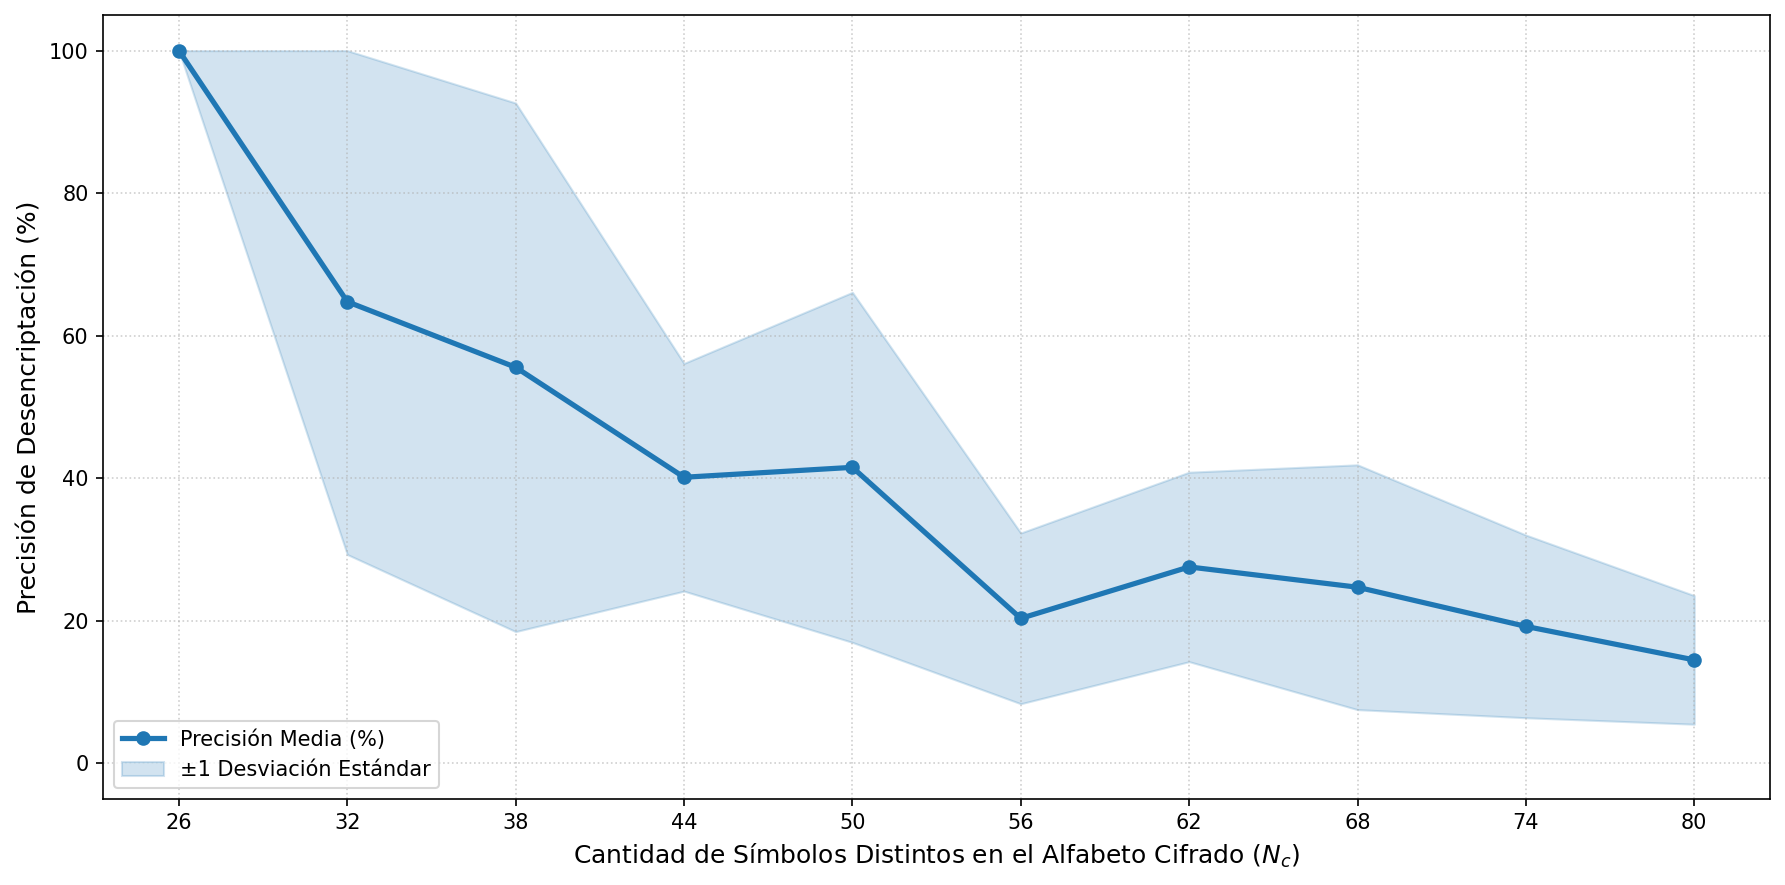

In [ ]:
# 3. Graficar la Curva de Ruptura
mean_accuracies = np.array(mean_accuracies)
std_accuracies = np.array(std_accuracies)

fig, ax1 = plt.subplots(figsize=(12, 6), dpi=150)

ax1.plot(homophones_range, mean_accuracies, marker='o', linewidth=2.5, color='#1f77b4', label='Precisión Media (%)')
ax1.fill_between(
    homophones_range,
    np.clip(mean_accuracies - std_accuracies, 0, 100),
    np.clip(mean_accuracies + std_accuracies, 0, 100),
    color='#1f77b4',
    alpha=0.2,
    label='±1 Desviación Estándar'
)

ax1.set_xlabel('Cantidad de Símbolos Distintos en el Alfabeto Cifrado ($N_c$)', fontsize=12)
ax1.set_ylabel('Precisión de Desencriptación (%)', fontsize=12)
ax1.set_ylim(-5, 105)
ax1.set_xticks(homophones_range)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='lower left', fontsize=10, frameon=True)

plt.tight_layout()
plt.savefig('curva_ruptura_zodiaco.png', dpi=300)
plt.show()

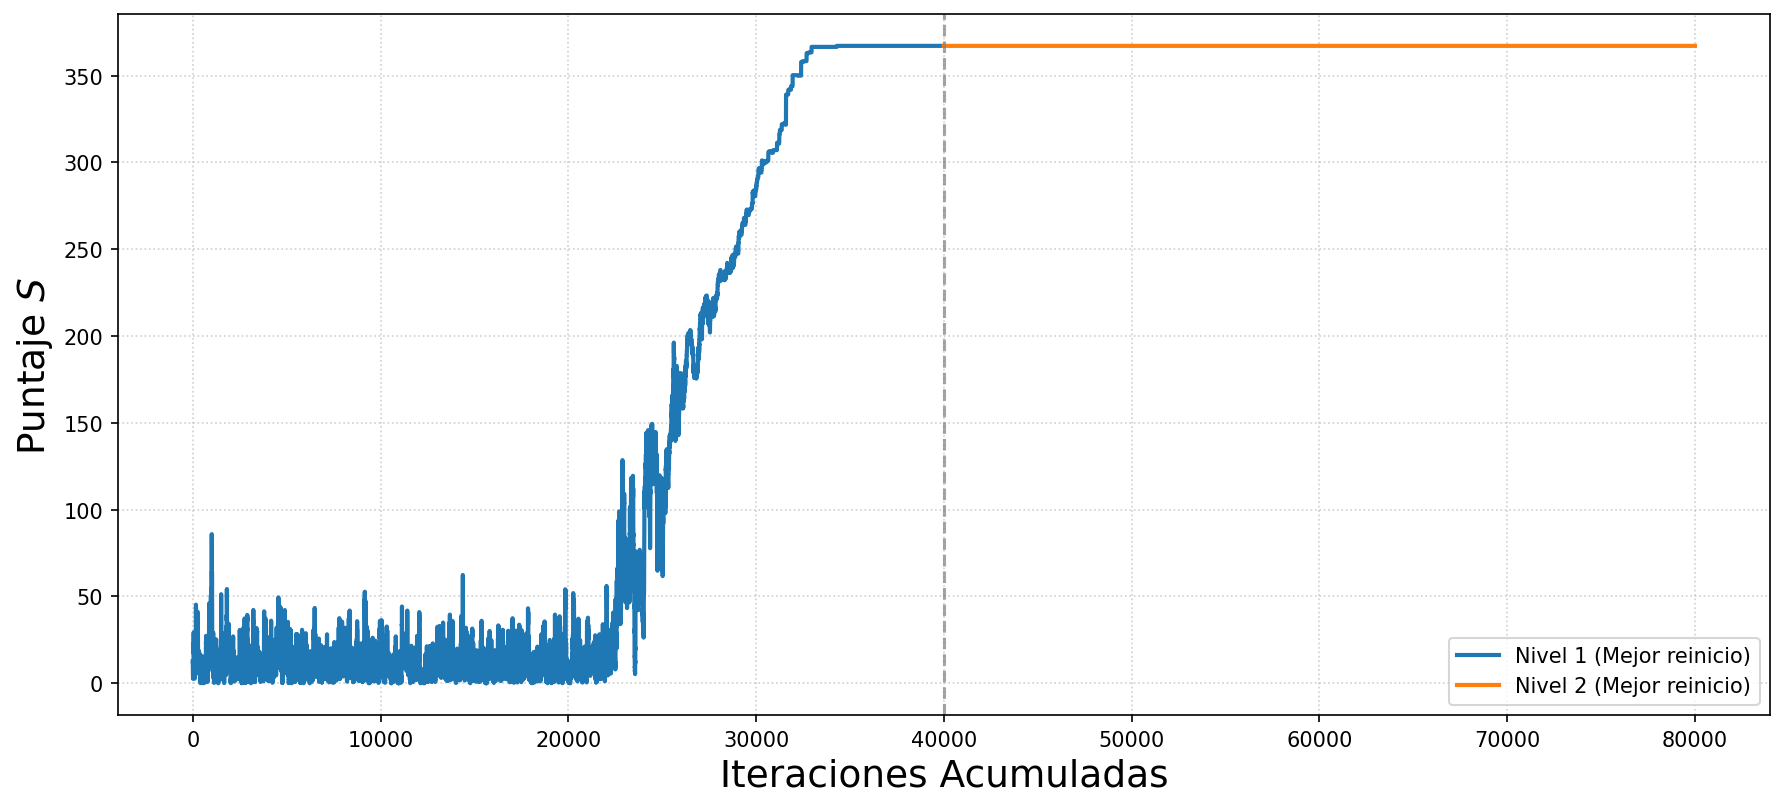

In [ ]:
# Ejecutar una vez sobre un caso interesante (ej. 40 símbolos en el texto de 300 chars)
texto_prueba = "INLATENINETEENSIXTYEIGHTANDNINETEENSIXTYNINEASERIESOFMYSTERIOUSCIPHEREDMESSAGESARRIVEDATLOCALNEWSPAPEROFFICESINSANFRANCISCOANDVALLEJOTHEAUTHORCLAIMEDTHATTHEHIDDENMESSAGECONTAINEDHISREALIDENTITYANDCHALLENGEDPOLICEANDCRYPTOGRAPHERSAROUNDTHECOUNTRYTOBREAKTHECOMPLEXHOMOPHONICSUBSTITUTIONCODEQUICKLY"

random.seed(42)
np.random.seed(42)

C_text = create_homophonic_cipher(texto_prueba, num_homophones=42)
cipher_alphabet = sorted(list(set(C_text)))
C_indices = message_to_indices(C_text, cipher_alphabet)

K_best, best_score, all_scores = simulated_annealing(
    C_indices,
    steps=40_000,
    n=6,
    ngram=log6gram,
    beta0=0.00001,
    betaN=100,
    reheat=0.5,
    levels=3,
    restarts=3
)

proposed = decrypt_message(C_indices, K_best, plaintext_alphabet)
acc_final = accuracy(proposed, texto_prueba, verbose=False)

plt.figure(figsize=(12, 5.5), dpi=150)

colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
offset = 0
steps_per_run = 40_000

for lvl in sorted(set(k[0] for k in all_scores.keys())):
    # Tomar la trayectoria del reinicio que alcanzó mayor score en este nivel
    restarts_in_lvl = [all_scores[k] for k in all_scores if k[0] == lvl]
    best_traj = max(restarts_in_lvl, key=lambda arr: np.max(arr))

    x_vals = np.arange(offset, offset + len(best_traj))
    plt.plot(x_vals, best_traj, color=colors[(lvl-1) % len(colors)], linewidth=2, label=f'Nivel {lvl} (Mejor reinicio)')

    if lvl > 1:
        plt.axvline(x=offset, color='gray', linestyle='--', alpha=0.7)
        #plt.text(offset + 500, np.min(best_traj), 'Recalentamiento\n(Reheat)', fontsize=9, color='#444444')

    offset += len(best_traj)

#plt.title(f'Evolución del Puntaje durante el Recocido Simulado (Precisión Final: {acc_final:.1f}%)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Iteraciones Acumuladas', fontsize=18)
plt.ylabel('Puntaje $S$ ', fontsize=18)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.savefig('convergencia_multinivel.png', dpi=300)
plt.show()

Iniciando matriz experimental (3 largos x 3 símbolos x 5 semillas = 45 ejecuciones)...
[ 0.2 min] Largo N=150 | Símbolos=30 (M=0.20) -> 100.0% ±  0.0%
[ 0.3 min] Largo N=150 | Símbolos=45 (M=0.30) ->  24.5% ±  0.0%
[ 0.5 min] Largo N=150 | Símbolos=60 (M=0.40) ->   7.9% ±  0.0%
[ 0.7 min] Largo N=300 | Símbolos=30 (M=0.10) ->  99.7% ±  0.0%
[ 0.8 min] Largo N=300 | Símbolos=45 (M=0.15) ->   1.4% ±  0.0%
[ 1.0 min] Largo N=300 | Símbolos=60 (M=0.20) ->   9.5% ±  0.0%
[ 1.2 min] Largo N=500 | Símbolos=30 (M=0.06) ->  99.6% ±  0.0%
[ 1.4 min] Largo N=500 | Símbolos=45 (M=0.09) ->  99.6% ±  0.0%
[ 1.5 min] Largo N=500 | Símbolos=60 (M=0.12) ->  97.8% ±  0.0%

TABLA DE RESULTADOS (Precisión Media ± Desviación Estándar y Multiplicidad)
        30 símbolos 45 símbolos 60 símbolos
N = 150      100.0%       24.5%        7.9%
N = 300       99.7%        1.4%        9.5%
N = 500       99.6%       99.6%       97.8%


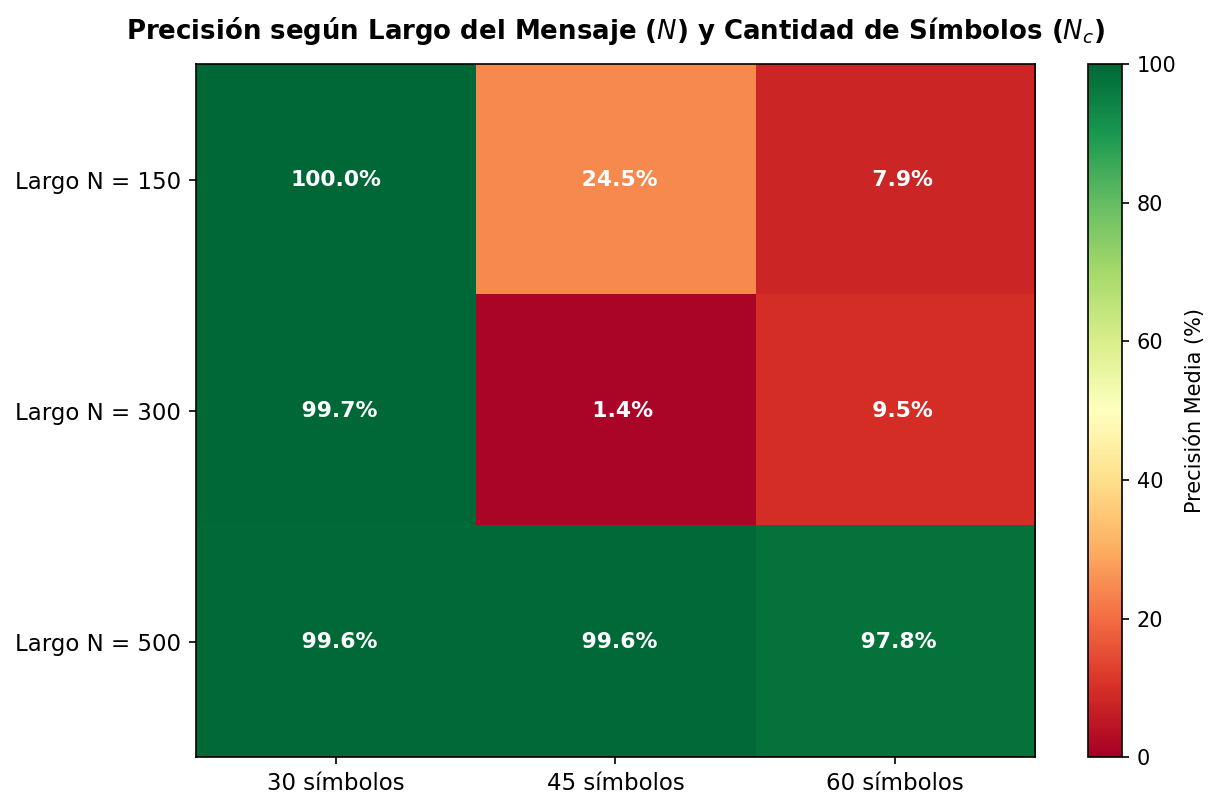

In [ ]:
import time
import pandas as pd

# 1. Definir los 3 textos de distinto largo (150, 300 y 500 caracteres)
textos = {
    150: "DETECTIVESINVESTIGATEDTHECRYPTICLETTERSANDCIPHERSSENTTONEWSPAPERSINNORTHERNCALIFORNIADURINGTHELATENINETEENSIXTIESHOPINGTOUNCOVERHIDDENCLUESABOUTTHECASE",
    300: "INLATENINETEENSIXTYEIGHTANDNINETEENSIXTYNINEASERIESOFMYSTERIOUSCIPHEREDMESSAGESARRIVEDATLOCALNEWSPAPEROFFICESINSANFRANCISCOANDVALLEJOTHEAUTHORCLAIMEDTHATTHEHIDDENMESSAGECONTAINEDHISREALIDENTITYANDCHALLENGEDPOLICEANDCRYPTOGRAPHERSAROUNDTHECOUNTRYTOBREAKTHECOMPLEXHOMOPHONICSUBSTITUTIONCODEQUICKLY",
    500: "FOROVERFIFTYAGOCRYPTOGRAPHERSMATHEMATICIANSANDAMATEURDETECTIVESATTEMPTEDTOSOLVETHEFAMOUSTHREEHUNDREDFORTYCHARACTERCIPHERATTRIBUTEDTOTHEZODIACKILLERUNLIKETHEFIRSTMESSAGEWHICHWASBROKENBYASCHOOLTEACHERANDHISWIFEINJUSTAFEWDAYSTHESECONDCIPHERREMAINEDUNSOLVEDFORDECADESBECAUSEITCOMBINEDHOMOPHONICSUBSTITUTIONWITHADIAGONALTRANSPOSITIONPATTERNTHATDISRUPTEDSTANDARDLETTERFREQUENCYANALYSISUNTILCOMPUTERASSISTEDSTATISTICALMETHODSANDNGRAMMODELSFINALLYREVEALEDTHEHIDDENPLAINTEXTINYEARSTWOTHOUSANDTWENTY"
}

homophones_list = [30, 45, 60]
num_seeds = 10


tabla_texto = {}
matriz_medias = np.zeros((len(textos), len(homophones_list)))

print("Iniciando matriz experimental (3 largos x 3 símbolos x 5 semillas = 45 ejecuciones)...")
start_time = time.time()

for i, (largo, msg) in enumerate(textos.items()):
    tabla_texto[f"N = {largo}"] = {}

    for j, num_h in enumerate(homophones_list):
        accs = []

        for seed in range(num_seeds):
            random.seed(seed)
            np.random.seed(seed)

            C_text = create_homophonic_cipher(msg, num_homophones=num_h)
            cipher_alphabet = sorted(list(set(C_text)))
            C_indices = message_to_indices(C_text, cipher_alphabet)

            K_best, _, _ = simulated_annealing(
                C_indices,
                steps=50_000,
                n=6,
                ngram=log6gram,
                beta0=0.00001,
                betaN=100,
                reheat=0.5,
                levels=1,
                restarts=1
            )

            proposed = decrypt_message(C_indices, K_best, plaintext_alphabet)
            acc = accuracy(proposed, msg, verbose=False)
            accs.append(acc)

        mean_val = np.mean(accs)
        std_val = np.std(accs)
        mult = num_h / largo

        matriz_medias[i, j] = mean_val
        tabla_texto[f"N = {largo}"][f"{num_h} símbolos"] = f"{mean_val:5.1f}%"

        elapsed = (time.time() - start_time) / 60
        print(f"[{elapsed:4.1f} min] Largo N={largo} | Símbolos={num_h} (M={mult:.2f}) -> {mean_val:5.1f}% ± {std_val:4.1f}%")


df_resultados = pd.DataFrame(tabla_texto).T
print("\n" + "="*75)
print("TABLA DE RESULTADOS (Precisión Media ± Desviación Estándar y Multiplicidad)")
print("="*75)
print(df_resultados.to_string())


fig, ax = plt.subplots(figsize=(8.5, 5.5), dpi=150)
im = ax.imshow(matriz_medias, cmap="RdYlGn", vmin=0, vmax=100, aspect="auto")


ax.set_xticks(np.arange(len(homophones_list)))
ax.set_yticks(np.arange(len(textos)))
ax.set_xticklabels([f"{h} símbolos" for h in homophones_list], fontsize=11)
ax.set_yticklabels([f"Largo N = {l}" for l in textos.keys()], fontsize=11)


for i, largo in enumerate(textos.keys()):
    for j, num_h in enumerate(homophones_list):
        texto_celda = tabla_texto[f"N = {largo}"][f"{num_h} símbolos"].replace(" (", "\n(")
        color_texto = "black" if 25 < matriz_medias[i, j] < 80 else "white"
        ax.text(j, i, texto_celda, ha="center", va="center", color=color_texto, fontweight="bold", fontsize=10.5)

plt.colorbar(im, ax=ax, label="Precisión Media (%)")
ax.set_title("Precisión según Largo del Mensaje ($N$) y Cantidad de Símbolos ($N_c$)", fontsize=12.5, fontweight="bold", pad=12)
plt.tight_layout()
plt.savefig("matriz_largo_vs_simbolos.png", dpi=300)
plt.show()